In [1]:
import cv2 as cv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import skimage as ski

import numpy.ma as ma

import scipy as sp

import statistics as st

In [2]:
from itertools import cycle

In [3]:
# plt.figure(figsize=(11, 7))
matplotlib.rcParams['figure.dpi'] = 200
matplotlib.rcParams['figure.figsize'] = [6.4, 4.9]

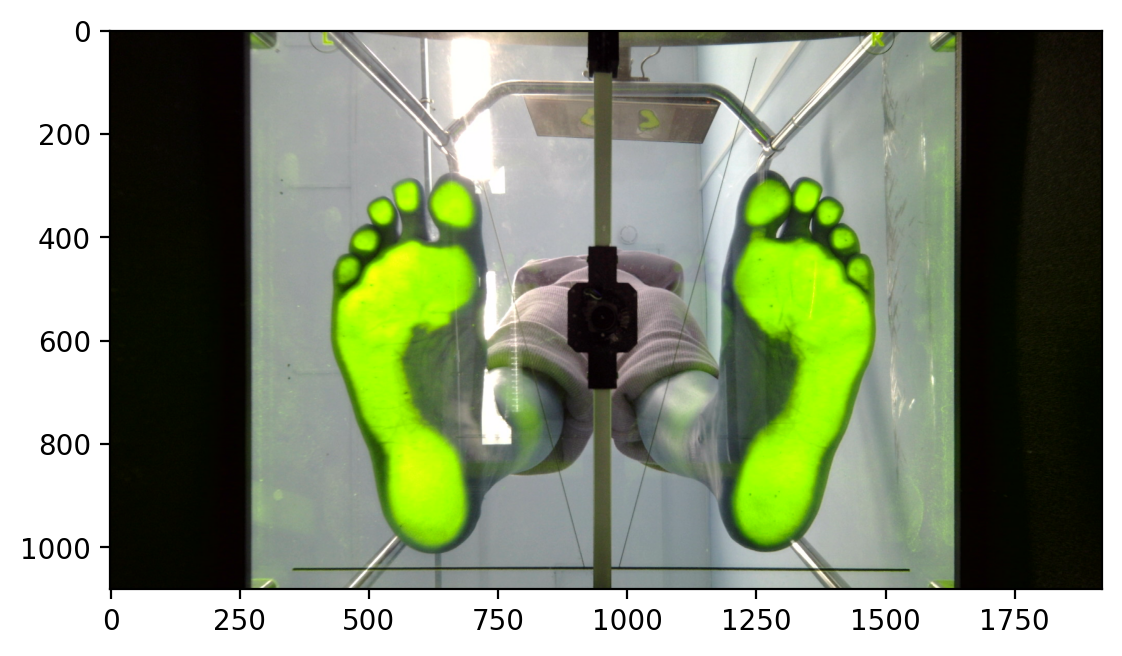

In [4]:
image = cv.imread("/home/dima/Documents/альбрехт/обработка изображений/default/images/Img (copy 7).png")

plt.imshow(image)

In [5]:
def split_foot(image):
    leftPad = 280
    rightPad = 1920 - 1630
    assert image.shape == (1080, 1920, 3)
    return image[:,leftPad:880,:], image[:,1025:-rightPad,:]

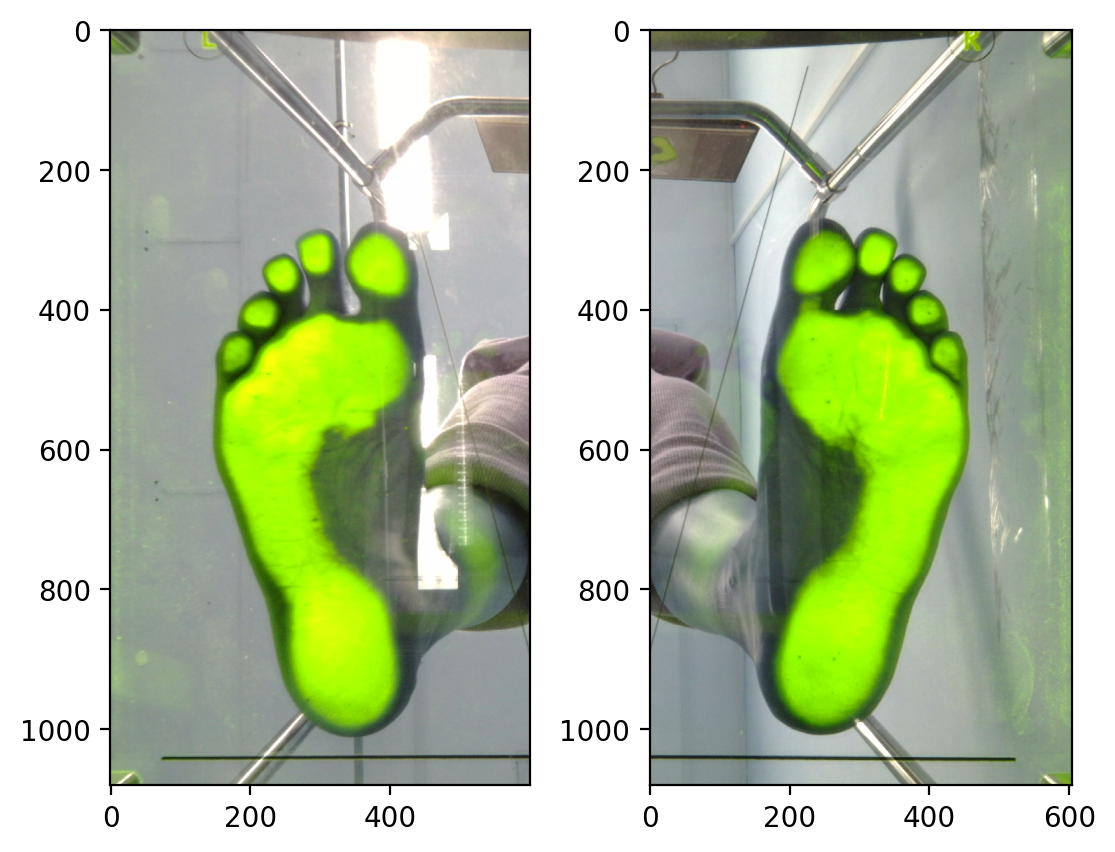

In [6]:
footL, footR = split_foot(image)
fig, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(footL)
ax2.imshow(footR)

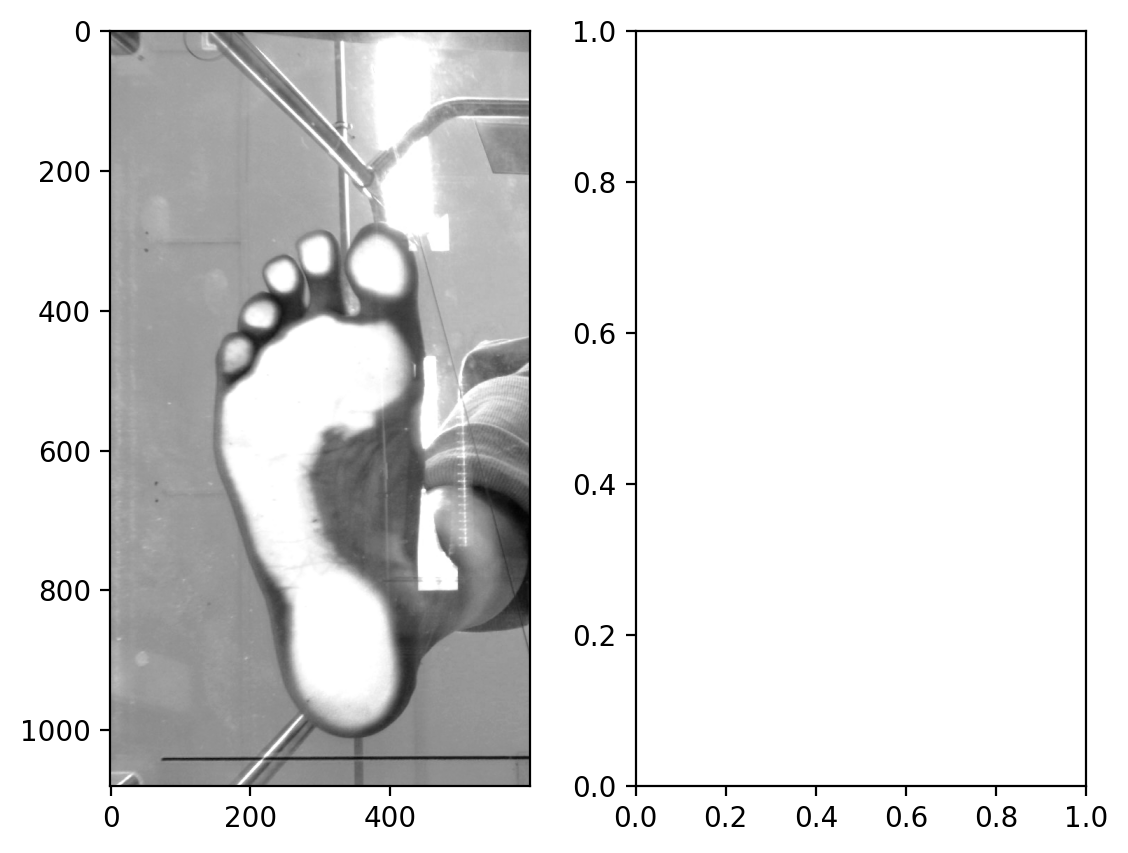

In [7]:
foot = footL

footHsv = ski.color.rgb2hsv(foot)
# footHsv = cv.cvtColor(foot, cv.COLOR_RGB2HSV)

# plt.plot(footHsv[:,:,0])
# np.min(footHsv[:,:,0])

sobelHsv = ski.filters.sobel(footHsv[:, :, 2])
sobelHsv = ski.util.img_as_ubyte(sobelHsv)

clean_mask_bool = ski.morphology.remove_small_objects(sobelHsv, min_size=10, connectivity=1)

fig, (ax1, ax2) = plt.subplots(1, 2)

ax1.imshow(footHsv[:,:,2], 'gray')
# ax1.imshow(sobelHsv, 'gray')
# ax2.imshow(clean_mask_bool, 'gray')

# fig.colorbar(ax1)

In [8]:
# maskedFoot = footHsv[footHsv[:,:,0] <= 90. & footHsv[:,:,0] >= 30.]
# maskedArr = ma.masked_inside(footHsv[:,:,0], 30, 90)
# maskedArr.data[1000, 500]
# footHsv[]
# maskedArr.mask
# maskedArr.data
# footHsv.shape
# plt.imshow(maskedArr, 'gray', vmin=0., vmax=180.)

(array([ 22718.,   8510.,  17906.,  19150.,  13345.,  18204.,  25790.,
         70379.,  80815., 371183.]),
 array([0.  , 0.04, 0.08, 0.12, 0.16, 0.2 , 0.24, 0.28, 0.32, 0.36, 0.4 ]),
 <BarContainer object of 10 artists>)

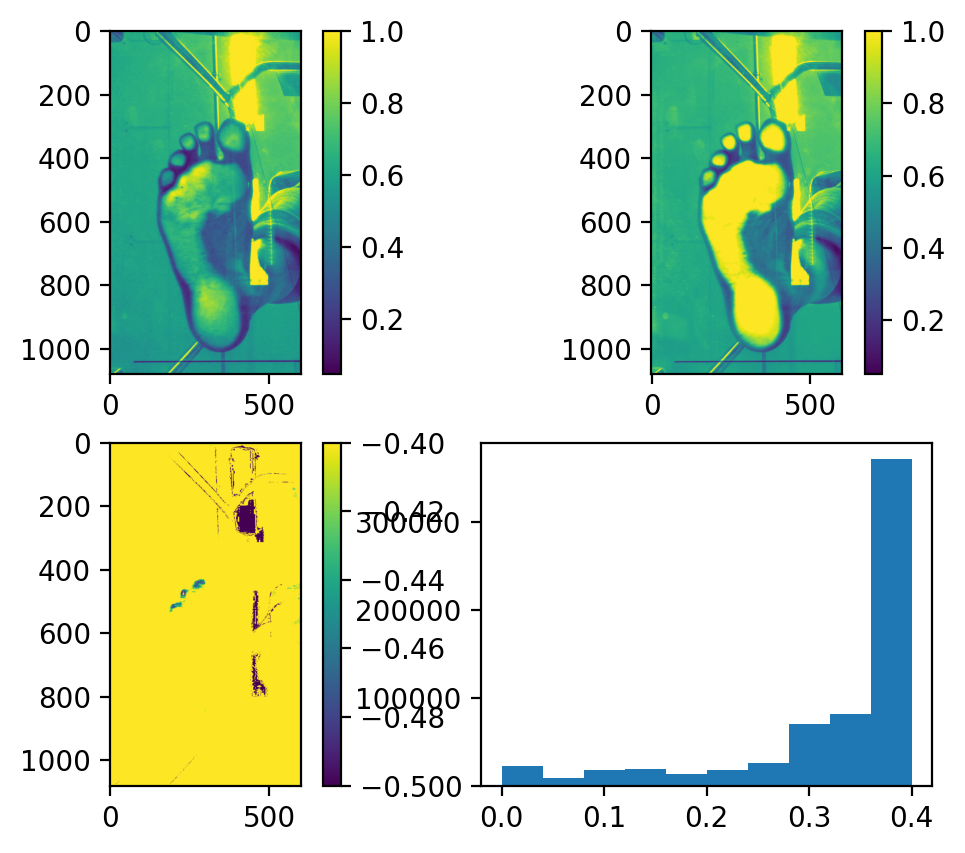

In [9]:
footHsv = ski.color.rgb2hsv(foot)
foot = ski.util.img_as_float(foot)

fig, axs = plt.subplots(2, 2)

axs = axs.flatten()

im = axs[0].imshow(foot[:,:,0])
plt.colorbar(im, ax=axs[0])

im = axs[1].imshow(foot[:,:,1])
plt.colorbar(im, ax=axs[1])

diff = cv.bitwise_and(foot[:,:,0], foot[:,:,1]) - foot[:,:,0]

_, diff2 = cv.threshold(diff, -0.4, 1, cv.THRESH_TRUNC)
diff = diff - diff2

# mask = (hue >= 30) & (hue <= 55)

# footHsv[:,:,0][~mask] = 0  # Modify original array

# diff = diff[diff

# diff = diff + np.abs(np.min(diff))

im = axs[2].imshow(diff2)
plt.colorbar(im, ax=axs[2])


axs[3].hist(diff.flatten())

# labels = ski.measure.label(diff)

# axs[4].imshow(ski.color.label2rgb(labels))


255 27574


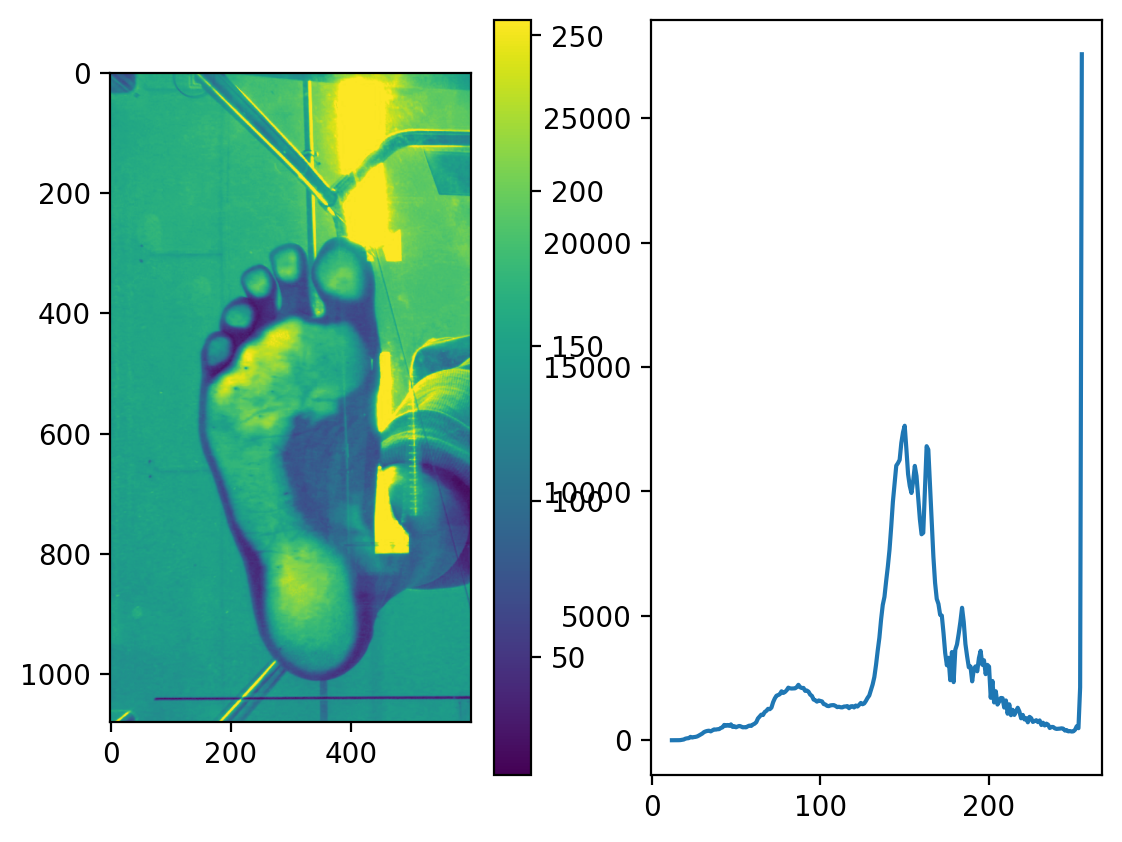

In [10]:
footHsv = ski.color.rgb2hsv(foot)
# foot = ski.util.img_as_float(foot)
foot = ski.util.img_as_ubyte(foot)

fig, axs = plt.subplots(1, 2)

# axs = axs.flatten()

r = foot[:,:, 0]
g = foot[:,:,1]
b = foot[:,:,2]

hist, bins = ski.exposure.histogram(r)
# plt.(bins, hist)
# print(hist, bins)
axs[1].plot(bins, hist)

im = axs[0].imshow(r)

fig.colorbar(im, ax=axs[0])

mode, Mcount = sp.stats.mode(r.flatten())
print(mode, Mcount)

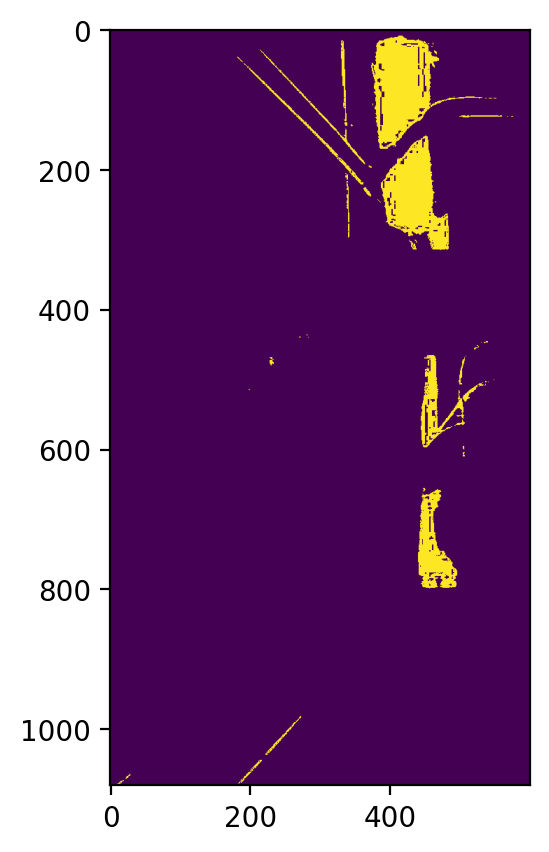

In [11]:
_, thImg = cv.threshold(r, mode - 1, 1, cv.THRESH_BINARY)

# print(np.count_nonzero(thImg))
plt.imshow(thImg)

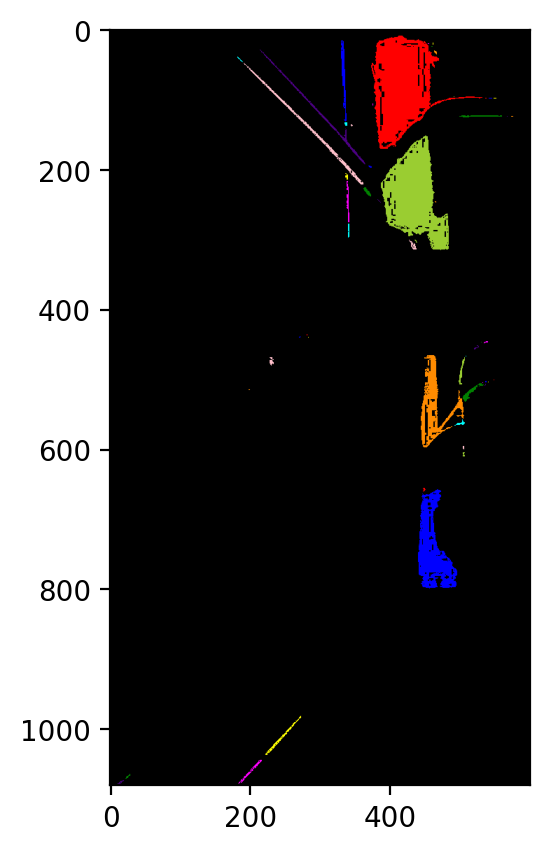

In [12]:
labels = ski.measure.label(thImg, connectivity=2)

plt.imshow(ski.color.label2rgb(labels))

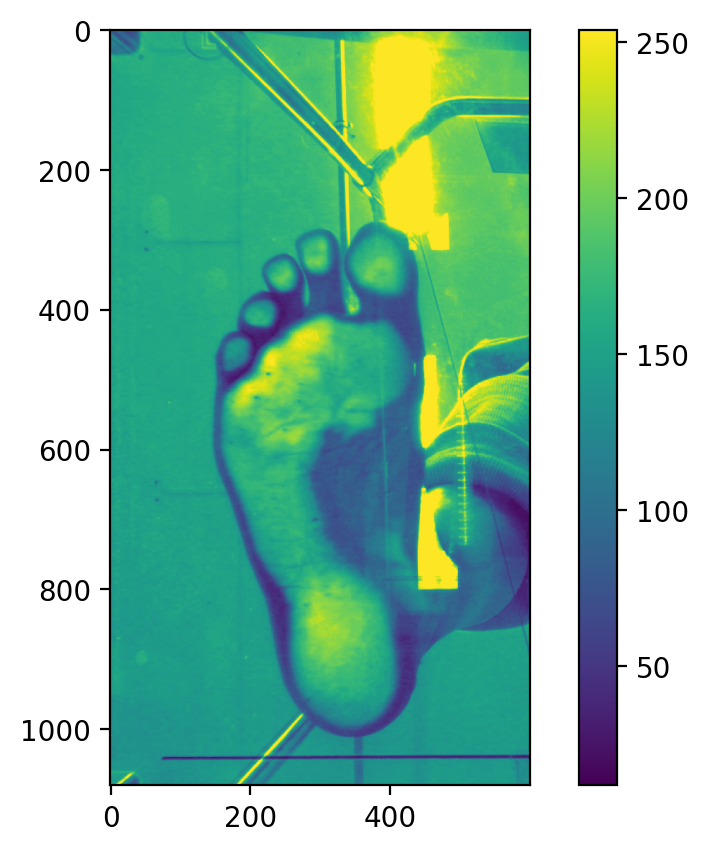

In [13]:
diff = r - thImg

plt.imshow(diff)
plt.colorbar()



0 1


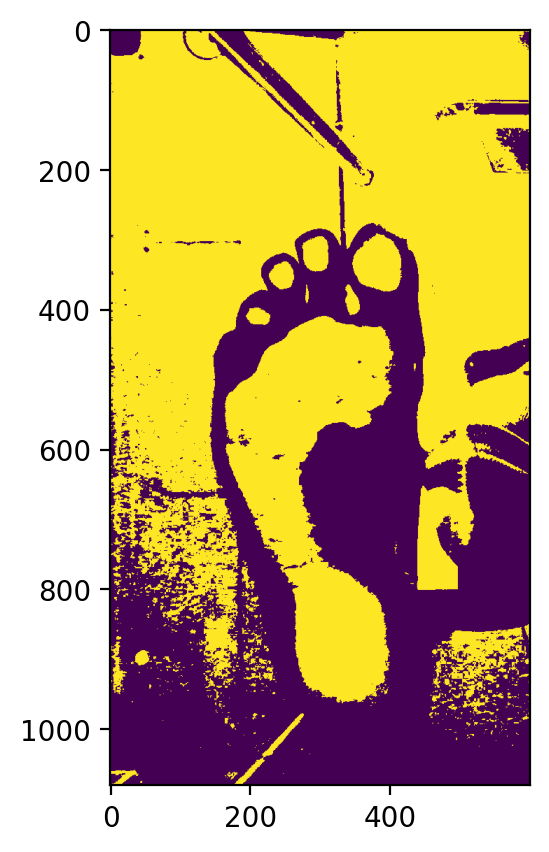

In [16]:
rFlat = r.flatten()
mode = st.mode(rFlat[rFlat != 255])

_, thImg = cv.threshold(r, mode - 1, 1, cv.THRESH_BINARY)
# mask = r < (mode - 1)

# rDiff[:,:][mask] = 0
# rDiff[:,:][~mask] = 1
print(np.min(thImg), np.max(thImg))

plt.imshow(thImg)

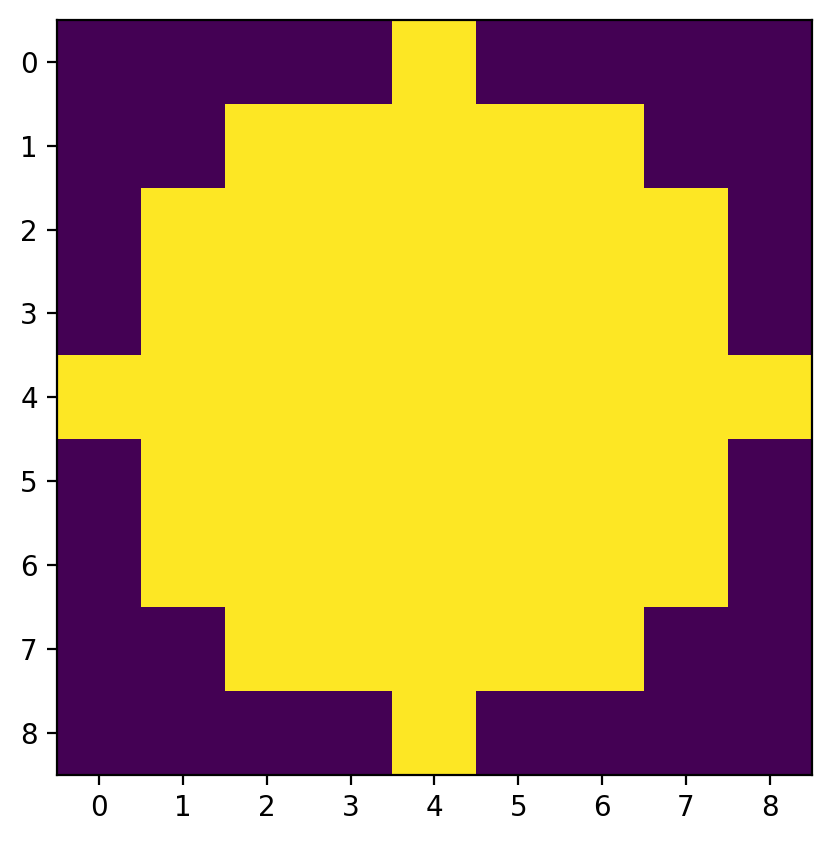

In [42]:
mask = ski.morphology.disk(4)
plt.imshow(mask)

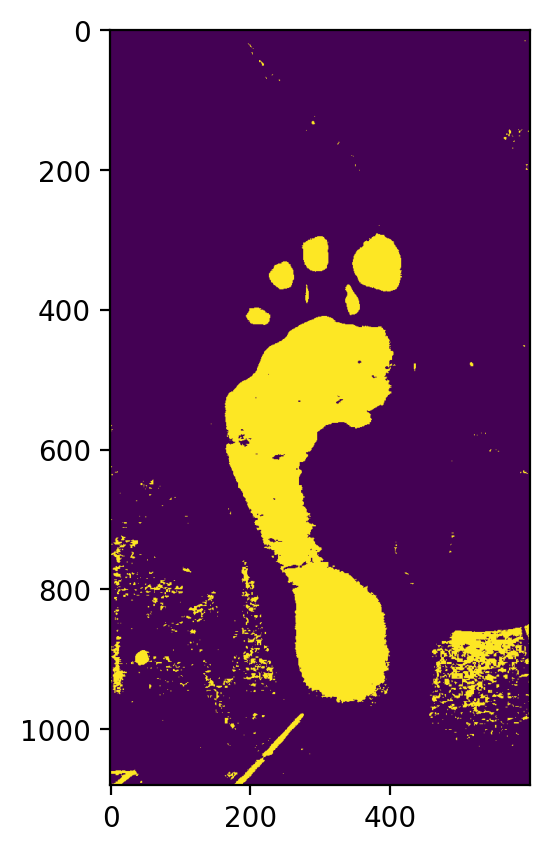

In [43]:
plt.imshow(ski.segmentation.flood_fill(thImg, (200, 200), 0))

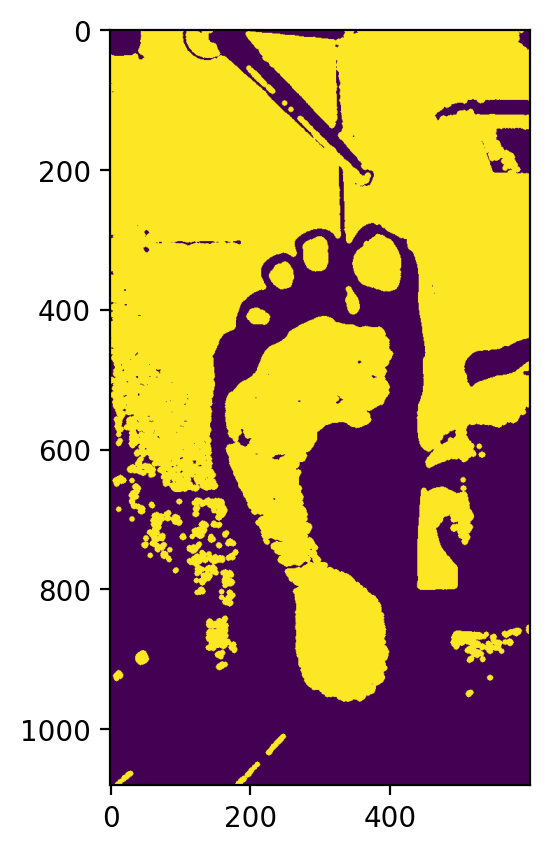

In [44]:
ppfff = ski.morphology.binary_opening(thImg, footprint=mask)

plt.imshow(ppfff)

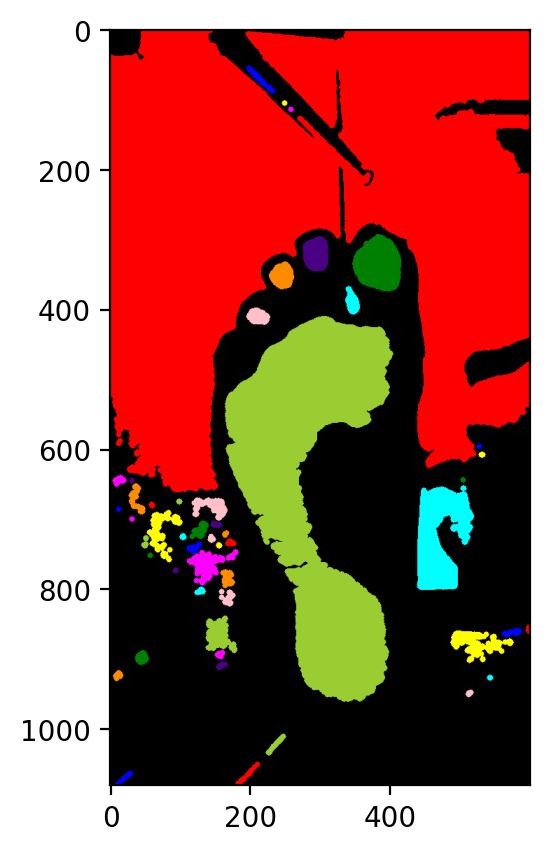

In [54]:
labels = ski.measure.label(ppfff, connectivity=1)

plt.imshow(ski.color.label2rgb(labels))

# labels = ski.morphology.remove_small_objects(labels, min_size=300)

ppfff_rsh = ski.morphology.remove_small_holes(ppfff, 500)
labels = ski.measure.label(ppfff_rsh, connectivity=1)
plt.imshow(ski.color.label2rgb(labels))


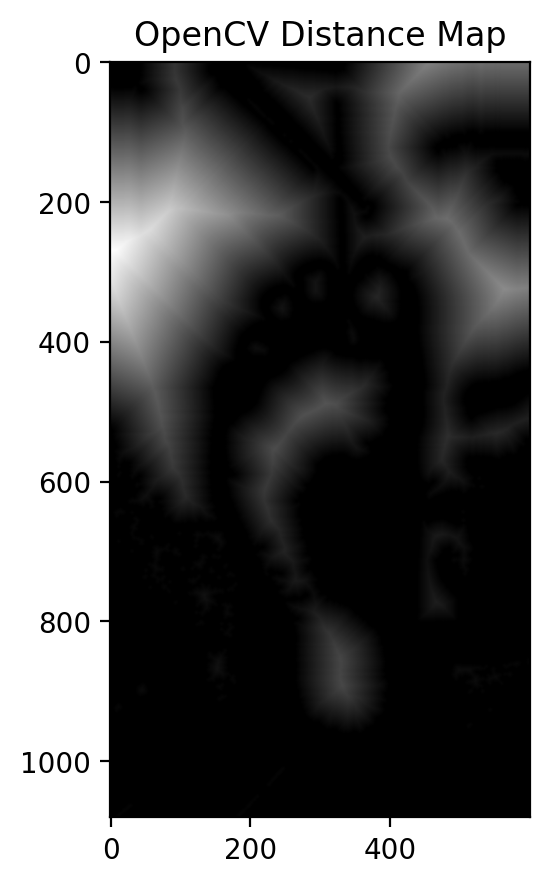

In [60]:
ppfff_rsh = np.asarray(ppfff_rsh, dtype=np.uint8)
distance_map = cv.distanceTransform(ppfff_rsh, cv.DIST_L2, 3)

# Normalize the distance map for visualization (optional, distance_map is float32)
# The values will range from 0 (background) to the maximum distance (center)
distance_map_normalized = cv.normalize(distance_map, None, 0, 255, cv.NORM_MINMAX, cv.CV_8UC1)

plt.imshow(distance_map_normalized, cmap='gray')
plt.title('OpenCV Distance Map')
plt.show()

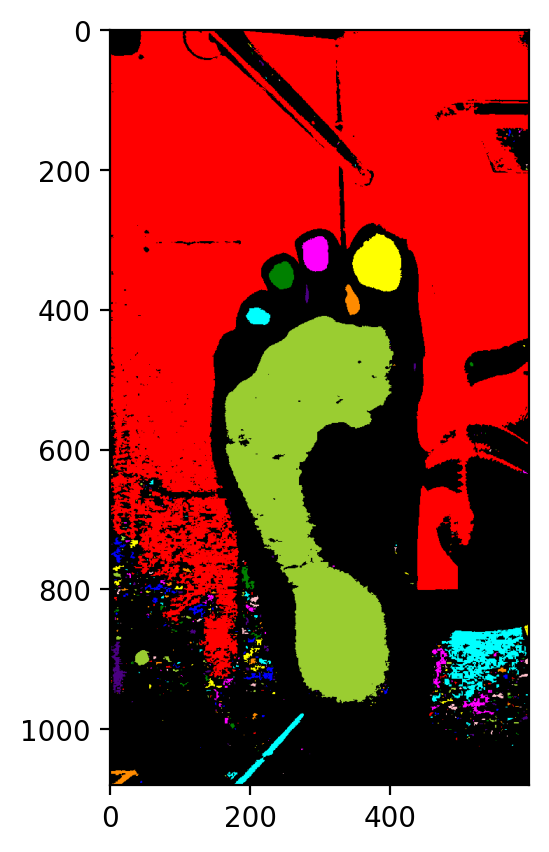

In [516]:
labels = ski.measure.label(thImg, connectivity=2)

plt.imshow(ski.color.label2rgb(labels))

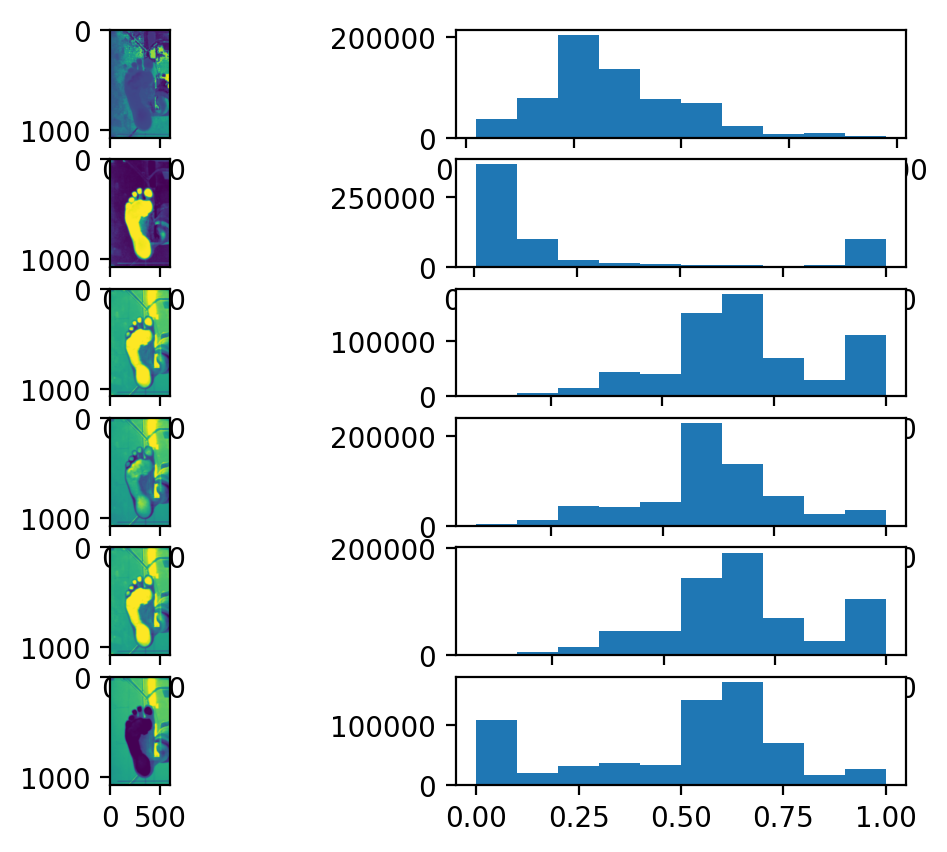

In [441]:
footHsv = ski.color.rgb2hsv(foot)
foot = ski.util.img_as_float(foot)

fig, axs = plt.subplots(6, 2)

axs = axs.flatten()

for axi, channeli in zip(range(0, 6, 2), cycle([0, 1, 2])):
    # ax = axs[axi]
    channel = footHsv[:, :, channeli]
    
    channel = ski.filters.gaussian(channel, sigma=3, preserve_range=True)

    axs[axi].imshow(channel)
    axs[axi + 1].hist(channel.flatten())

for axi, channeli in zip(range(6, 12, 2), cycle([0, 1, 2])):
    # ax = axs[axi]
    channel = foot[:, :, channeli]
    
    channel = ski.filters.gaussian(channel, sigma=3, preserve_range=True)

    axs[axi].imshow(channel)
    axs[axi + 1].hist(channel.flatten())

In [ ]:
footHsv = ski.color.rgb2hsv(foot) * 180
hue = footHsv[:,:,0]

# Most efficient - direct boolean mask
mask = (hue >= 30) & (hue <= 55)

footHsv[:,:,0][~mask] = 0  # Modify original array

# plt.imshow(footHsv[:,:,0], 'gray', vmin=0., vmax=180.)

fig, axs = plt.subplots(3, 4)

# axs = axs.flatten()

# axs[0].imshow(footHsv[:,:,0], 'gray')
# axs[1].imshow(footHsv[:,:,1], 'gray')
# axs[2].imshow(footHsv[:,:,2], 'gray')

# axs[3].imshow(foot[:,:,0], 'gray')
# axs[4].imshow(foot[:,:,1], 'gray')
# axs[5].imshow(foot[:,:,2], 'gray')

channeli = 0
i = 0

for yi in range(3):
    for xi in range(4):
        if i <= 2:
            channel = footHsv[:, :, channeli]
            channeli += 1
        else:
            if i == 6:
                channeli = 0
            else:
                channeli += 1
                
            channel = foot[:,:, channeli]
        
        channel = ski.filters.gaussian(channel, sigma=3, preserve_range=True)
    
        channelLabels = ski.measure.label(channel, connectivity=2)
    
        # axs[i].imshow(hsvChannel, 'gray')
        print(f'i: {i} N={len(channelLabels)}')
        
        # axs[i].imshow(ski.color.label2rgb(channelLabels))

        axs[yi, xi].imshow(channel, 'gray')
        # print(row, col)
        # axs[(i+1) // 4, (i+1) // 2].hist(channel)
            # matplotlib.axes.Axes
        i += 1

# plt.colorbar()

In [375]:
footSmooth = ski.filters.gaussian(foot, sigma=0, preserve_range=False)
footHsv = ski.color.rgb2hsv(footSmooth)

hue = footHsv[:,:,0]
value = footHsv[:,:,1]
# sobelValue = ski.filters.sobel(foot[:,:,2])
# g = foot[:, :, 1]

# Most efficient - direct boolean mask
# mask = (hue >= 30) & (hue <= 55)
# plt.imshow(mask)
# Маркируем все связные области (1, 2, 3...)
labels = ski.measure.label(value, connectivity=1)

# Вычисляем свойства регионов (площадь и т.д.)
regionsprops = ski.measure.regionprops(labels)

# areas = [region.area for region in regionsprops]
largest_region = sorted(regionsprops, key=lambda region: region.area, reverse=True)

# final_mask = np.repeat(np.expand_dims(final_mask, 2), 3, axis=2)
# .shape
# print(final_mask)
# plt.imshow(
# print(footL[:,:,0].shape, np.max(footL), foot * final_mask))
print(len(largest_region))

178


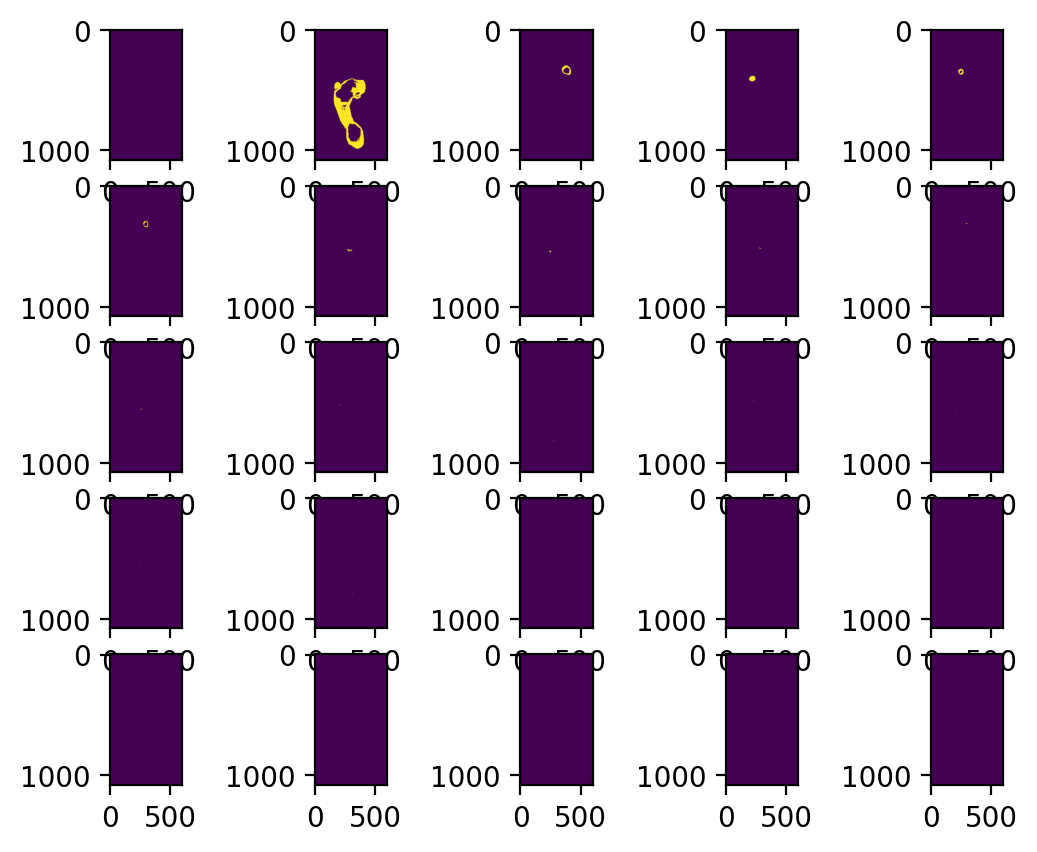

In [376]:
fig, axs = plt.subplots(5, 5)
axs = axs.flatten()

for n, ax in enumerate(axs):
    final_mask = (labels == largest_region[n - 1].label)
    ax.imshow(final_mask)
    ax.sharex(axs[0])
    ax.sharey(axs[0])

# maskedImage = foot * final_mask

# maskedGrayImage = ski.color.rgb2gray(maskedImage)

# elevation_map = ski.filters.sobel(maskedGrayImage)
# plt.imshow(elevation_map, 'gray')
plt.show()

(1080, 600)


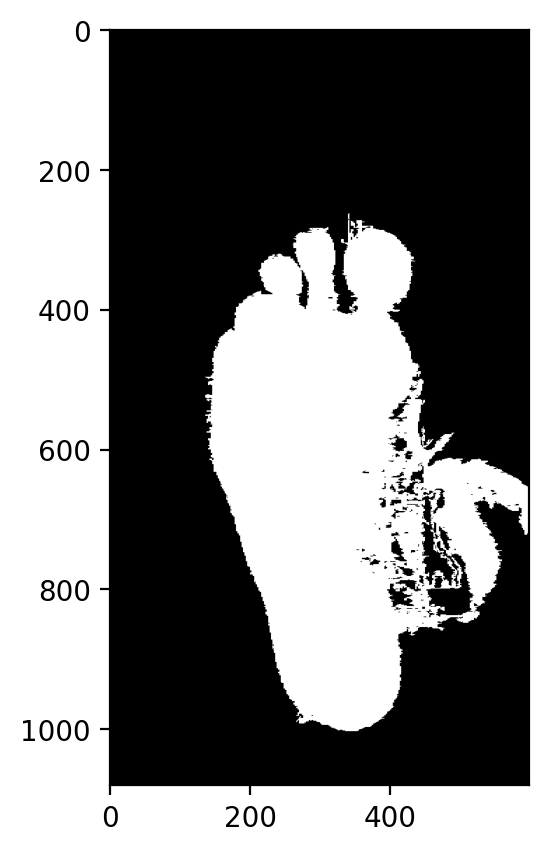

In [220]:
footHsv = ski.color.rgb2hsv(foot) * 180
hue = footHsv[:,:,0]

mask = (hue >= 30) & (hue <= 55)

# Удаляем объекты размером меньше 500 пикселей (подберите число под ваш случай)
# connectivity=1 означает, что пиксели считаются соседями только по вертикали/горизонтали
clean_mask_bool = ski.morphology.remove_small_objects(mask, min_size=10000, connectivity=0)

plt.imshow(clean_mask_bool, 'gray')
print(clean_mask_bool.shape)

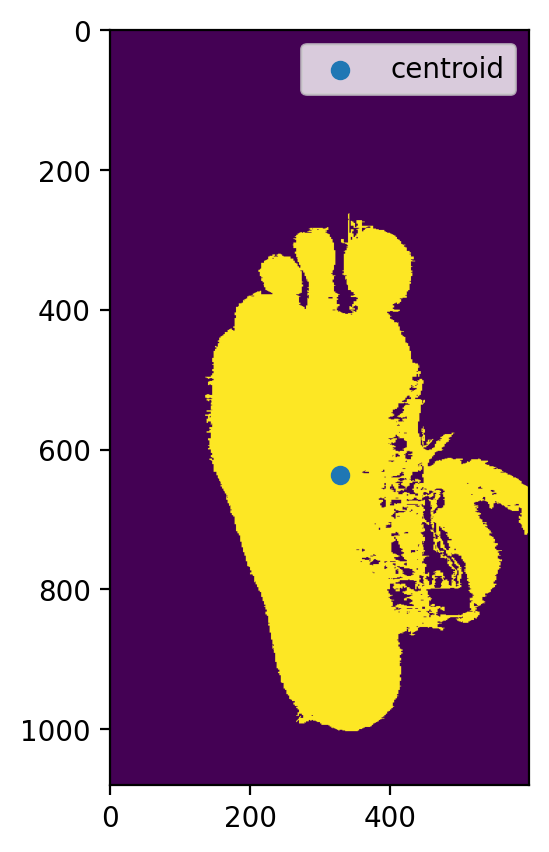

In [228]:
yC, xC = ski.measure.centroid(clean_mask_bool)

plt.imshow(clean_mask_bool)
plt.scatter(xC, yC, label='centroid')

plt.legend()

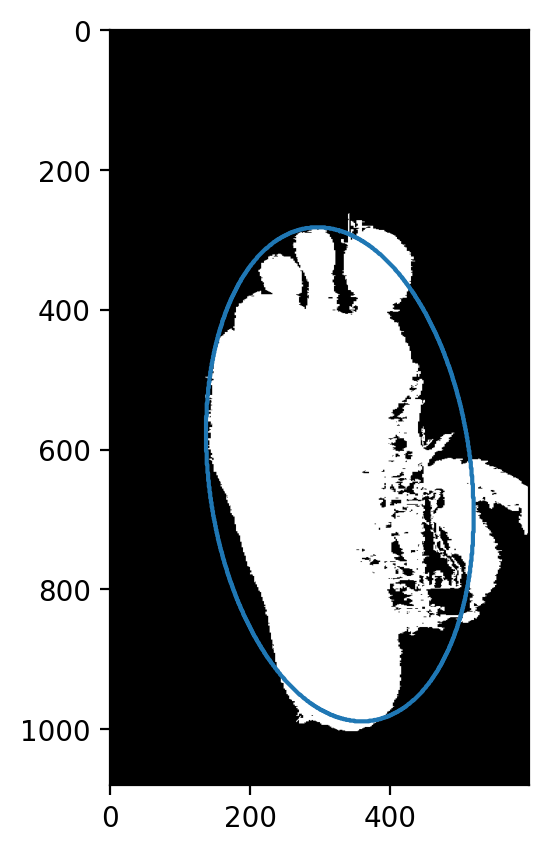

Center: (329.2, 636.5)
Axis: 710.3, 375.0
Angle: 0.1 rad


In [274]:
labels = ski.measure.label(clean_mask_bool, connectivity=2)

# Вычисляем свойства регионов (площадь и т.д.)
regionsprops = ski.measure.regionprops(labels)

# largest_region = sorted(regionsprops, key=lambda region: region.area, reverse=True)
props = regionsprops[0]

# 3. Извлекаем параметры эллипса
y0, x0 = props.centroid
orientation = props.orientation
major_axis = props.major_axis_length
minor_axis = props.minor_axis_length

# 4. Визуализация
fig, ax = plt.subplots()

# Расчет угла для Matplotlib:
# props.orientation - это угол в радианах между осью Y (строками) и главной осью.
# Matplotlib ожидает угол в градусах от оси X.
# Формула конвертации: 90 - (угол в градусах) или просто -degrees(orientation) в зависимости от осей.
# Для вертикально ориентированной стопы часто подходит:
angle_deg = -np.degrees(orientation)

# Создаем патч эллипса
# Обратите внимание: width и height здесь - это длины осей
# Так как orientation считается от Y, то major_axis (длинная) идет как height (по Y до поворота),
# а minor_axis как width.
# el = matplotlib.patches.Ellipse((x0, y0), width=minor_axis, height=major_axis, angle=angle_deg,
             # edgecolor='red', facecolor='none', linewidth=2)

# ax.add_patch(el)

rr, cc = ski.draw.ellipse_perimeter(np.uint(x0), np.uint(y0), np.uint(minor_axis / 2), np.uint(major_axis / 2), orientation=orientation)

angle = np.arctan2(rr - np.mean(rr), cc - np.mean(cc))
sorted_by_angle = np.argsort(angle)
rrs = rr[sorted_by_angle]
ccs = cc[sorted_by_angle]

ax.plot(rrs, ccs)
ax.imshow(clean_mask_bool, cmap='gray')
# ax.scatter(x0, y0, label='Centroid')
# plt.legend()
plt.show()

print(f"Center: ({x0:.1f}, {y0:.1f})")
print(f"Axis: {major_axis:.1f}, {minor_axis:.1f}")
print(f"Angle: {orientation:.1f} rad")
# print(xr.shape)

In [309]:
final_mask = np.repeat(np.expand_dims(clean_mask_bool, 2), 3, axis=2)

imgForAC = ski.color.rgb2gray(footL * final_mask)

imgForAC = ski.filters.gaussian(imgForAC, sigma=3, preserve_range=False)
# snake = ski.segmentation.active_contour(imgForAC, np.array([xr, yr]).T, alpha=0.001, beta=10, gamma=0.05)


In [322]:
snake = ski.segmentation.active_contour(imgForAC,
                                        np.array([rrs, ccs]).T,
                                        alpha=0.01,
                                        beta=1,
                                        gamma=0.001,
                                        w_line=0.,
                                        w_edge=1,
                                        max_num_iter=500
                                       )


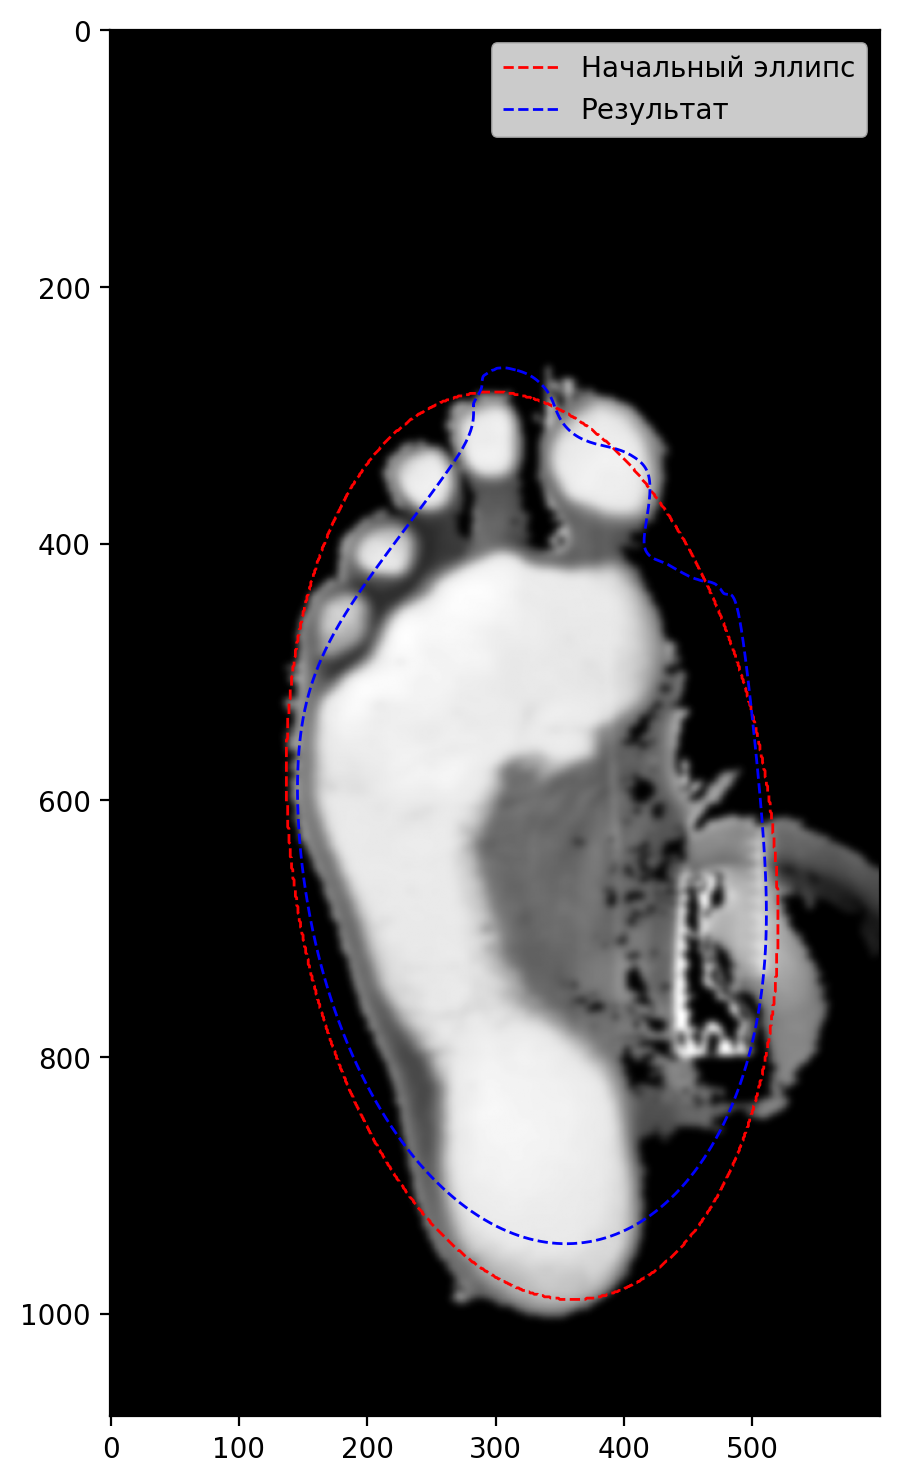

In [323]:
# Визуализация
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(imgForAC, cmap=plt.cm.gray)
ax.plot(rrs, ccs, '--r', lw=1, label='Начальный эллипс')
ax.plot(snake[:, 0], snake[:, 1], '--b', lw=1, label='Результат')
ax.legend()
plt.show()

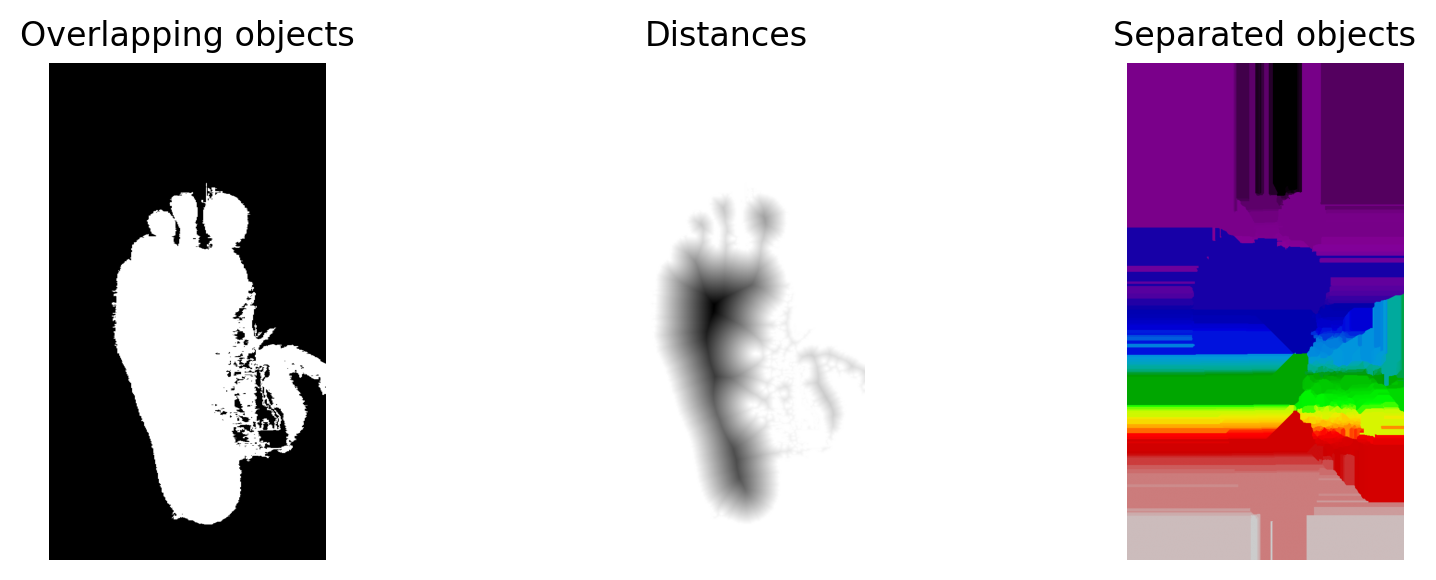

In [325]:
distance = sp.ndimage.distance_transform_edt(clean_mask_bool)
coords = ski.feature.peak_local_max(distance, footprint=np.ones((3, 3)), labels=clean_mask_bool)
mask = np.zeros(distance.shape, dtype=bool)
mask[tuple(coords.T)] = True
markers, _ = sp.ndimage.label(mask)
labels = ski.segmentation.watershed(-distance, markers, mask=clean_mask_bool)

fig, axes = plt.subplots(ncols=3, figsize=(9, 3), sharex=True, sharey=True)
ax = axes.ravel()

ax[0].imshow(clean_mask_bool, cmap=plt.cm.gray)
ax[0].set_title('Overlapping objects')
ax[1].imshow(-distance, cmap=plt.cm.gray)
ax[1].set_title('Distances')
ax[2].imshow(labels, cmap=plt.cm.nipy_spectral)
ax[2].set_title('Separated objects')

for a in ax:
    a.set_axis_off()

fig.tight_layout()
plt.show()

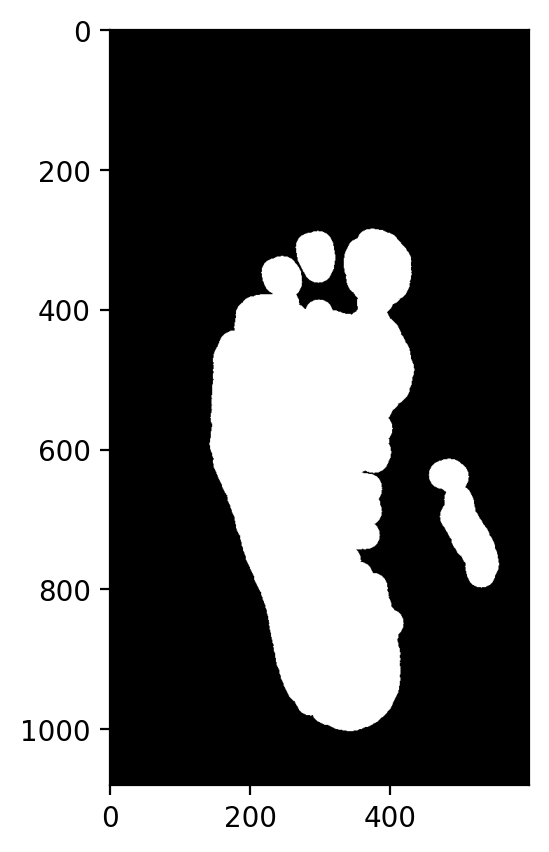

In [216]:
opened_mask = ski.morphology.binary_opening(clean_mask_bool, ski.morphology.disk(20))

# После открытия могут остаться совсем мелкие крошки, добиваем их фильтром по размеру
final_clean = ski.morphology.remove_small_objects(opened_mask, min_size=2000, connectivity=2)

plt.imshow(final_clean, 'gray')

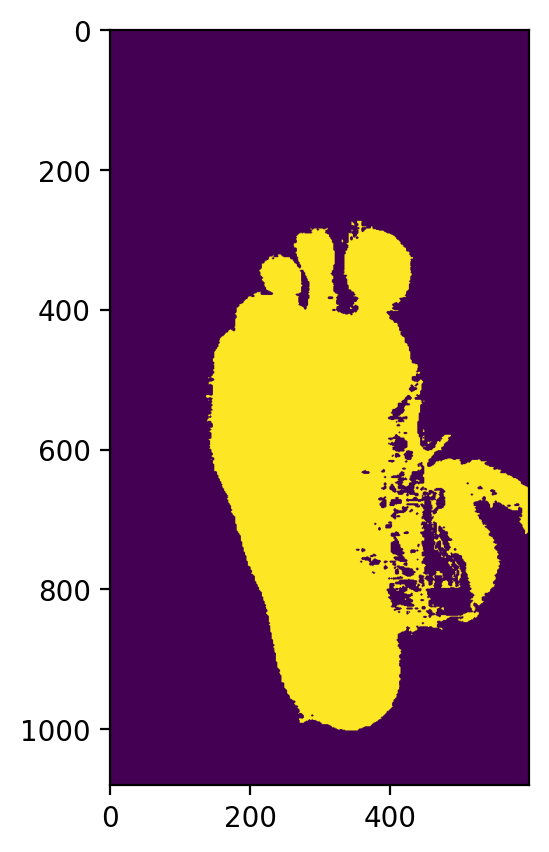

In [194]:
eroded = ski.morphology.binary_erosion(clean_mask_bool, ski.morphology.disk(1))

plt.imshow(eroded)

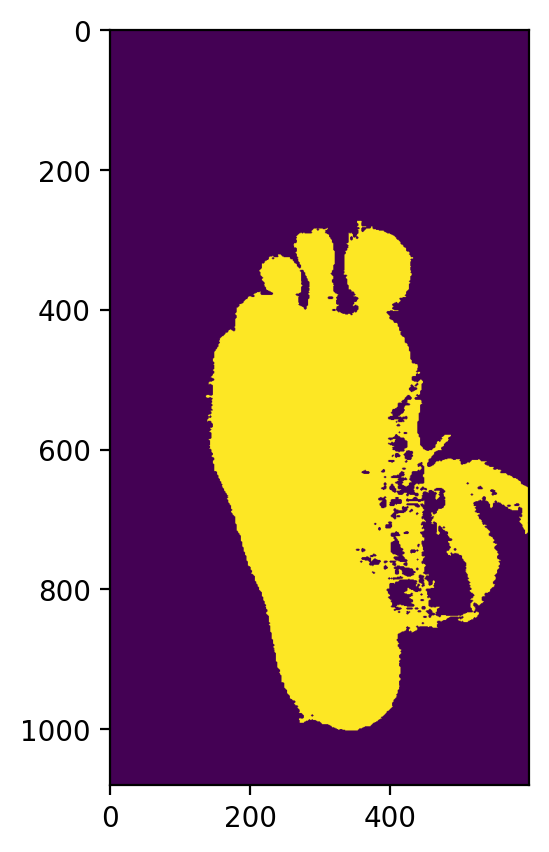

In [201]:
# 2. Оставляем только самый большой объект (стопу), мусор от ноги исчезнет
clean_eroded = ski.morphology.remove_small_objects(eroded, min_size=100000)
plt.imshow(clean_eroded)

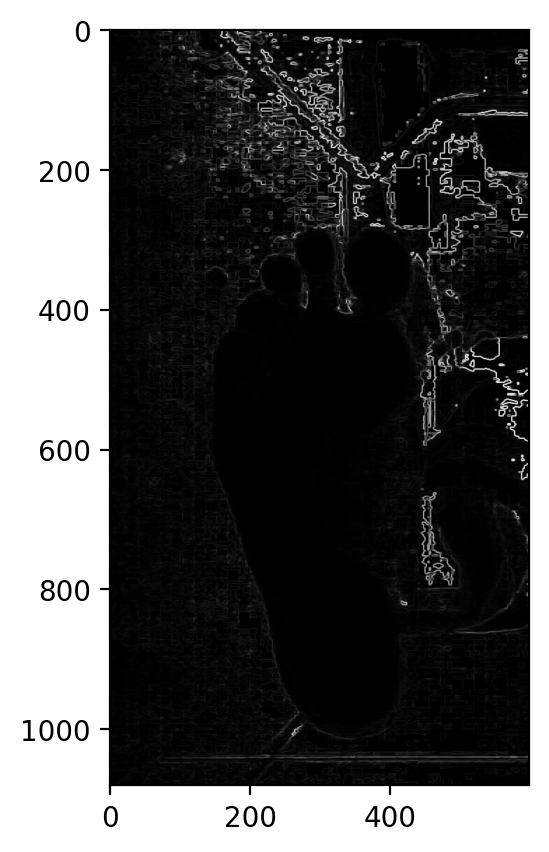

In [31]:
footHsv = ski.color.rgb2hsv(foot) * 180
hue = footHsv[:,:,0]

elevation_map = ski.filters.sobel(hue)

plt.imshow(elevation_map, 'gray')

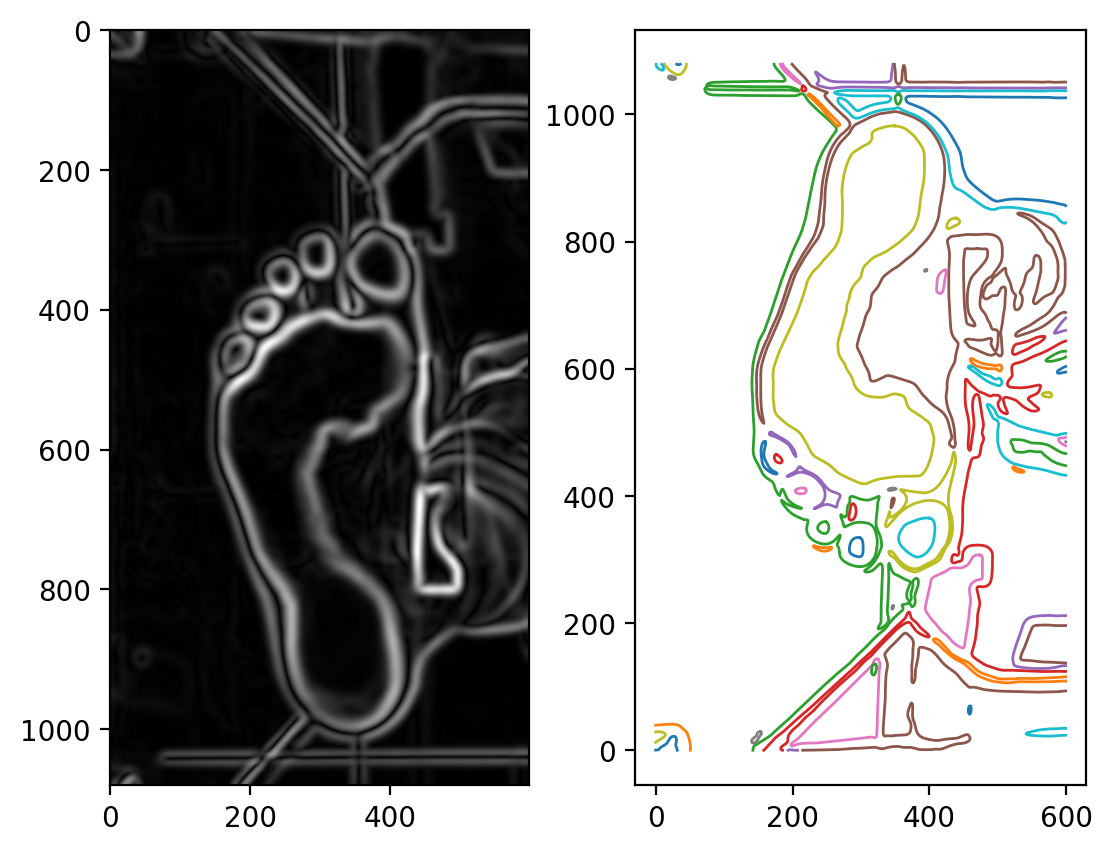

In [361]:
grayImg = ski.color.rgb2gray(foot)

grayImg = ski.filters.gaussian(grayImg, sigma=6, preserve_range=False)

fig, (ax1, ax2) = plt.subplots(1, 2)
elevation_map = ski.filters.sobel(grayImg)

ax1.imshow(elevation_map, 'gray')

distance = sp.ndimage.distance_transform_edt(elevation_map)

# ax2.imshow(-distance, cmap=plt.cm.gray)
# ax2.set_title('Distances')
# ax2.hist(elevation_map)
# ski.color.
contours = ski.measure.find_contours(elevation_map, 0.01)

# Display the image and plot all contours found

for contour in contours:
    ax2.plot(contour[:, 1], contour[:, 0], linewidth=1)
    
# ax2.imshow((1 - elevation_map), 'gray')

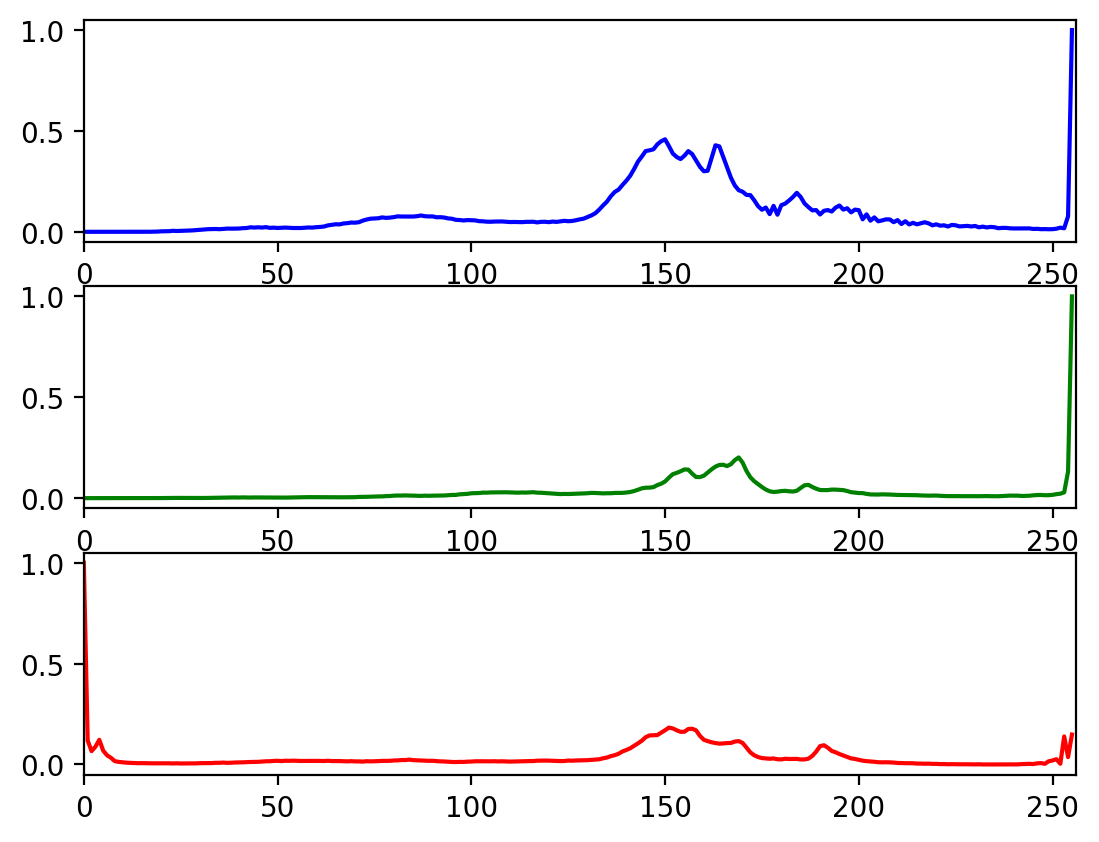

In [11]:
fig, axs = plt.subplots(3, 1)

color = ('b', 'g', 'r')
for i, col in enumerate(color):
    ax = axs[i]
    hist = cv.calcHist([foot], [i], None, [256], [0, 256])
    normHist = cv.normalize(hist, hist, 1, 0, cv.NORM_MINMAX, -1)
    ax.plot(hist, color=col)
    ax.set_xlim([0, 256])

# hist = cv.calcHist([foot[:,:,0]], [0], None, [256], [0, 256])

# normTypes = [cv.NORM_L1, cv.NORM_L2, cv.NORM_MINMAX]
# normNames = 'cv.NORM_L1, cv.NORM_L2, cv.NORM_MINMAX'.split(', ')


# for i, normType in enumerate(normTypes):
#     ax = axs[i]
#     print(f'Calculating norm using {normNames[i]}')
#     normHist = cv.normalize(hist, hist, 1, 0, normType, -1)
#     ax.plot(normHist)
#     ax.set_xlim([0, 256])

plt.show()

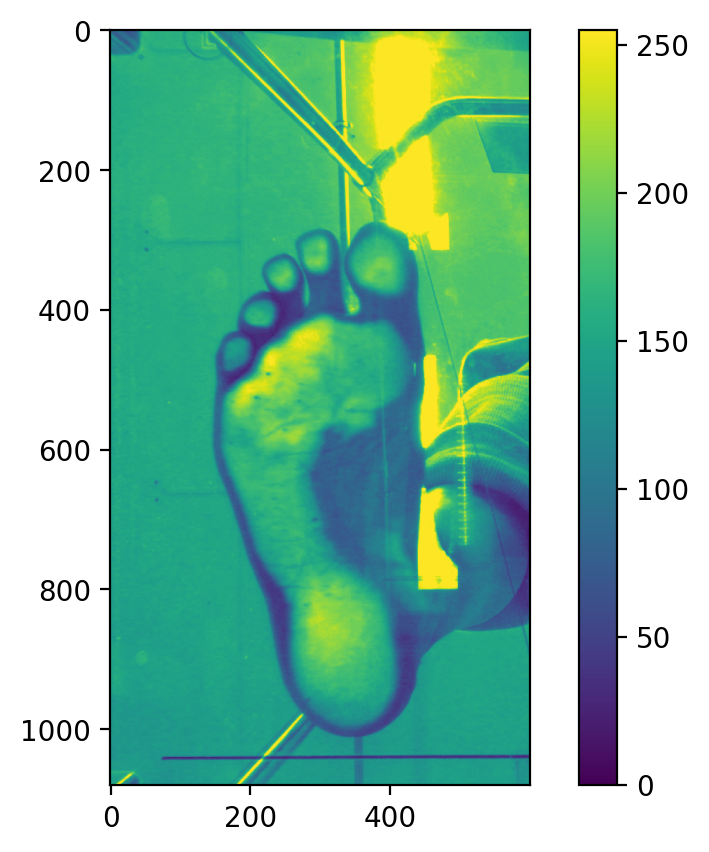

In [20]:

plt.imshow(foot[:,:,0], vmin=0, vmax=255)
plt.colorbar()

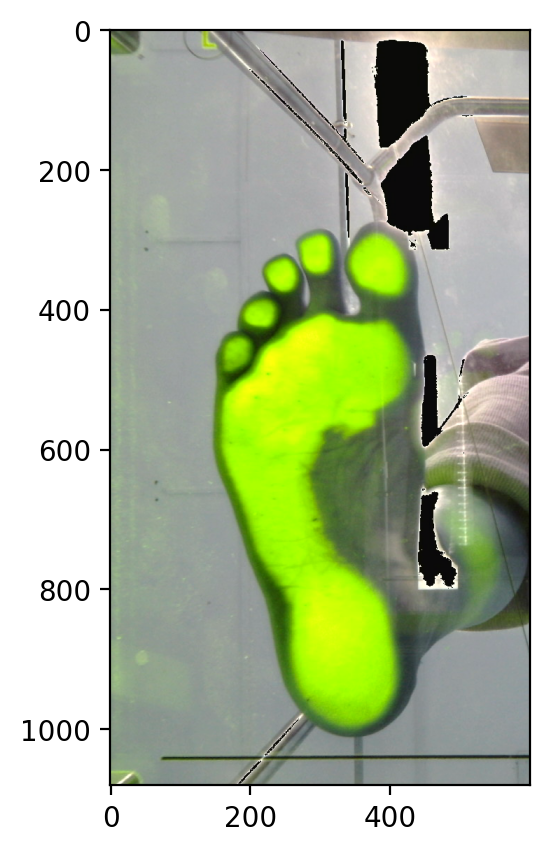

In [31]:
maskR = foot[:,:,0] > 245
maskG = foot[:,:,1] > 245
maskB = foot[:,:,2] > 245

mask = maskR & maskG & maskB
mask3d = np.repeat(np.expand_dims(mask, 2), 3, axis=2)


plt.imshow(foot - mask3d * 245)